# Bài 5 — Phân tích dữ liệu cháy rừng

**Dataset:** [1.88 Million US Wildfires](https://www.kaggle.com/datasets/rtatman/188-million-us-wildfires/data)

Cần có sẵn dữ liệu trong máy.
Dataset gốc là cơ sở dữ liệu SQLite. Lấy mẫu tối đa 100.000 dòng để phân tích bằng Pandas, các tổng số và thống kê theo năm được tính trực tiếp trên toàn bộ dữ liệu bằng SQLite.

Lưu ý: Cần tới gần 20 phút để upload file zip lên...

## 1. Đọc và kiểm tra dữ liệu theo từng cột

In [2]:
import os
import glob
import zipfile
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload file ZIP
uploaded = files.upload()

zip_file = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
)

# Giải nén dữ liệu
extract_dir = "/content/wildfire_data"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Giải nén thành công!")

# Tìm file SQLite sau khi giải nén
sqlite_files = glob.glob(
    os.path.join(extract_dir, "**", "*.sqlite"),
    recursive=True
)

if not sqlite_files:
    raise FileNotFoundError("Không tìm thấy file SQLite sau khi giải nén.")

db_path = sqlite_files[0]
print("File dữ liệu:", db_path)

# Kết nối SQLite
conn = sqlite3.connect(db_path)

print("Kết nối dữ liệu thành công!")

# Kiểm tra tên bảng và cấu trúc từng cột
print("Các bảng:", pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';", conn
)["name"].tolist())
columns = pd.read_sql_query("PRAGMA table_info(Fires);", conn)
display(columns[["name", "type"]])
# Lấy mẫu phân tán theo FOD_ID, tối đa 100.000 dòng
query = """
SELECT FOD_ID, FIRE_YEAR, DISCOVERY_DATE,
       STAT_CAUSE_DESCR, FIRE_SIZE, STATE
FROM Fires
WHERE FOD_ID % 19 = 0
LIMIT 100000
"""
df = pd.read_sql_query(query, conn)

print("Kích thước mẫu:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)

Saving FPA_FOD_20170508.sqlite.zip to FPA_FOD_20170508.sqlite (1).zip
Giải nén thành công!
File dữ liệu: /content/wildfire_data/FPA_FOD_20170508.sqlite
Kết nối dữ liệu thành công!
Các bảng: ['spatial_ref_sys', 'spatialite_history', 'sqlite_sequence', 'geometry_columns', 'spatial_ref_sys_aux', 'views_geometry_columns', 'virts_geometry_columns', 'geometry_columns_statistics', 'views_geometry_columns_statistics', 'virts_geometry_columns_statistics', 'geometry_columns_field_infos', 'views_geometry_columns_field_infos', 'virts_geometry_columns_field_infos', 'geometry_columns_time', 'geometry_columns_auth', 'views_geometry_columns_auth', 'virts_geometry_columns_auth', 'sql_statements_log', 'SpatialIndex', 'ElementaryGeometries', 'KNN', 'Fires', 'idx_Fires_Shape', 'idx_Fires_Shape_node', 'idx_Fires_Shape_rowid', 'idx_Fires_Shape_parent', 'NWCG_UnitIDActive_20170109']


,name,type
0,OBJECTID,INTEGER
1,FOD_ID,int32
2,FPA_ID,text(100)
3,SOURCE_SYSTEM_TYPE,text(255)
4,SOURCE_SYSTEM,text(30)
5,NWCG_REPORTING_AGENCY,text(255)
6,NWCG_REPORTING_UNIT_ID,text(255)
7,NWCG_REPORTING_UNIT_NAME,text(255)
8,SOURCE_REPORTING_UNIT,text(30)
9,SOURCE_REPORTING_UNIT_NAME,text(255)


Kích thước mẫu: (98978, 6)


,FOD_ID,FIRE_YEAR,DISCOVERY_DATE,STAT_CAUSE_DESCR,FIRE_SIZE,STATE
0,19,2004,2453329.5,Debris Burning,0.1,CA
1,38,2005,2453397.5,Arson,50.3,NC
2,57,2005,2453546.5,Lightning,2.0,OR
3,76,2005,2453554.5,Miscellaneous,0.1,MT
4,95,2005,2453546.5,Lightning,0.1,OR


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98978 entries, 0 to 98977
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   FOD_ID            98978 non-null  int64  
 1   FIRE_YEAR         98978 non-null  int64  
 2   DISCOVERY_DATE    98978 non-null  float64
 3   STAT_CAUSE_DESCR  98978 non-null  object 
 4   FIRE_SIZE         98978 non-null  float64
 5   STATE             98978 non-null  object 
dtypes: float64(2), int64(2), object(2)
memory usage: 4.5+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FOD_ID,98978.0,NaN,NaN,NaN,54868642.828154,101229245.649249,19.0,505594.75,1066441.5,19106452.25,300348276.0
FIRE_YEAR,98978.0,NaN,NaN,NaN,2003.711168,6.665287,1992.0,1998.0,2004.0,2009.0,2015.0
DISCOVERY_DATE,98978.0,NaN,NaN,NaN,2453064.023803,2435.388586,2448622.5,2451089.5,2453178.0,2455032.5,2457387.5
STAT_CAUSE_DESCR,98978,13,Debris Burning,22622,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FIRE_SIZE,98978.0,NaN,NaN,NaN,69.026141,2120.381716,0.0001,0.1,1.0,3.1,312918.3
STATE,98978,52,CA,9901,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Lọc các vụ cháy theo năm, bang và nguyên nhân

In [3]:
# Lọc theo năm
fire_2010 = df[df["FIRE_YEAR"] == 2010]

# Lọc theo bang California
fire_ca = df[df["STATE"] == "CA"]

# Lọc theo nguyên nhân sét
fire_lightning = df[df["STAT_CAUSE_DESCR"] == "Lightning"]

print("Số vụ cháy năm 2010:", len(fire_2010))
print("Số vụ cháy tại California:", len(fire_ca))
print("Số vụ cháy do sét:", len(fire_lightning))

Số vụ cháy năm 2010: 4180
Số vụ cháy tại California: 9901
Số vụ cháy do sét: 14689


## 3. Tính tổng số vụ cháy, diện tích bị ảnh hưởng và thống kê theo thời gian

In [4]:
# Tính trên toàn bộ dữ liệu, không chỉ trên mẫu
summary = pd.read_sql_query("""
SELECT COUNT(*) AS total_fires,
       SUM(FIRE_SIZE) AS total_area_acres
FROM Fires;
""", conn)

total_fires = int(summary.loc[0, "total_fires"])
total_area = summary.loc[0, "total_area_acres"]

print("Tổng số vụ cháy:", f"{total_fires:,}")
print("Tổng diện tích bị cháy:", f"{total_area:,.2f}", "acres")

# Thống kê số vụ cháy và diện tích theo năm trên toàn bộ dữ liệu
year_stats = pd.read_sql_query("""
SELECT FIRE_YEAR,
       COUNT(*) AS so_vu_chay,
       SUM(FIRE_SIZE) AS dien_tich_acres
FROM Fires
GROUP BY FIRE_YEAR
ORDER BY FIRE_YEAR;
""", conn)

display(year_stats.head())

Tổng số vụ cháy: 1,880,465
Tổng diện tích bị cháy: 140,132,549.55 acres


,FIRE_YEAR,so_vu_chay,dien_tich_acres
0,1992,67975,2199958.001
1,1993,61989,2191696.003
2,1994,75955,4116675.529
3,1995,71472,2049585.058
4,1996,75574,6005155.709


## 4. Xử lý ngày tháng, giá trị thiếu và dữ liệu trùng lặp

In [5]:
# Chuyển kiểu dữ liệu và ngày Julian sang datetime
df["FIRE_YEAR"] = pd.to_numeric(df["FIRE_YEAR"], errors="coerce")
df["FIRE_SIZE"] = pd.to_numeric(df["FIRE_SIZE"], errors="coerce")
df["DISCOVERY_DATE"] = pd.to_datetime(
    df["DISCOVERY_DATE"], unit="D", origin="julian", errors="coerce"
)
# Kiểm tra giá trị thiếu
print("Giá trị thiếu trước khi xử lý:")
print(df.isnull().sum())
# Điền nguyên nhân chưa xác định; bỏ dòng thiếu các thông tin thiết yếu
df["STAT_CAUSE_DESCR"] = df["STAT_CAUSE_DESCR"].fillna("Unknown")
df = df.dropna(subset=["FIRE_YEAR", "DISCOVERY_DATE", "STATE", "FIRE_SIZE"])
# Kiểm tra và xóa bản ghi trùng theo mã định danh FOD_ID
print("Số dòng trùng FOD_ID:", df.duplicated(subset=["FOD_ID"]).sum())
df = df.drop_duplicates(subset=["FOD_ID"])
print("Kích thước sau xử lý:", df.shape)

Giá trị thiếu trước khi xử lý:
FOD_ID              0
FIRE_YEAR           0
DISCOVERY_DATE      0
STAT_CAUSE_DESCR    0
FIRE_SIZE           0
STATE               0
dtype: int64
Số dòng trùng FOD_ID: 0
Kích thước sau xử lý: (98978, 6)


## 5. Thống kê bằng NumPy và trực quan hóa bằng Matplotlib/Seaborn

Diện tích cháy trung bình: 69.02614119945845
Diện tích cháy trung vị: 1.0
Diện tích cháy lớn nhất: 312918.3
Độ lệch chuẩn: 2120.371004482651


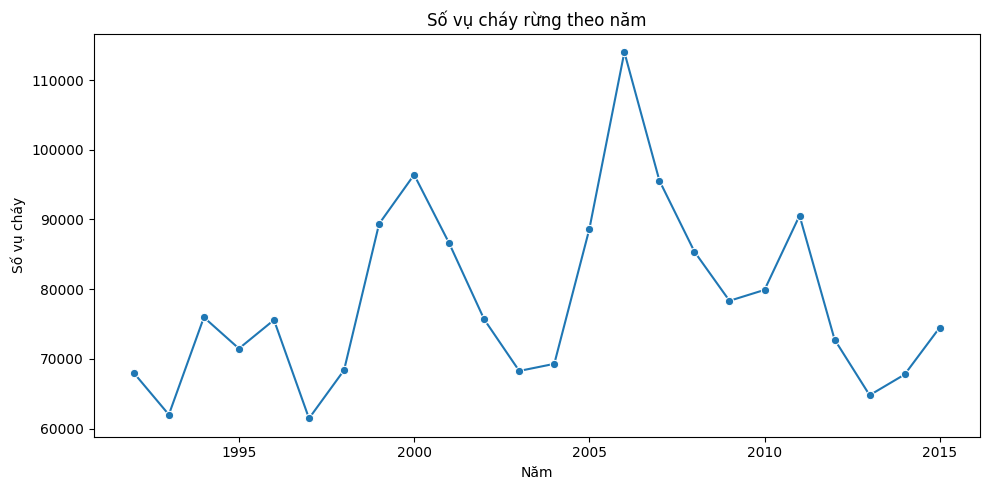

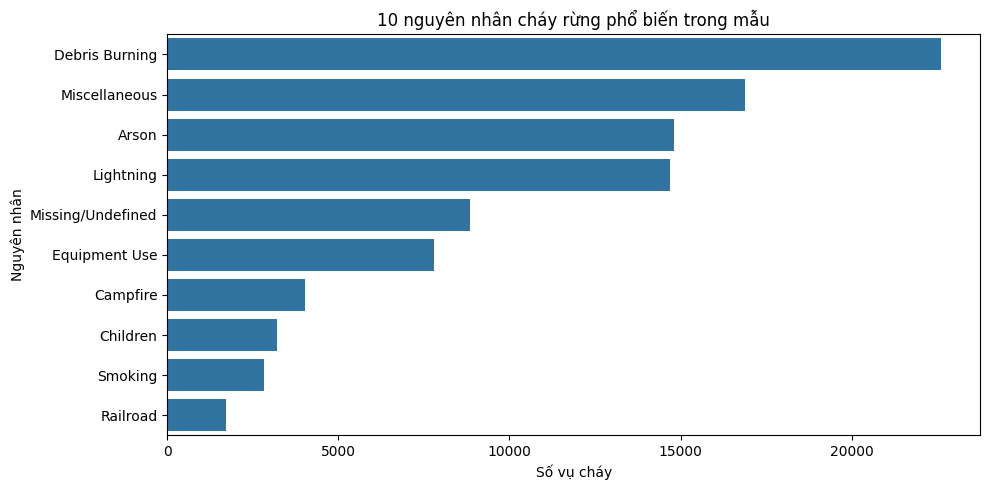

In [6]:
# Các phép thống kê NumPy trên mẫu dữ liệu đã làm sạch
sizes = df["FIRE_SIZE"].to_numpy()
print("Diện tích cháy trung bình:", np.mean(sizes))
print("Diện tích cháy trung vị:", np.median(sizes))
print("Diện tích cháy lớn nhất:", np.max(sizes))
print("Độ lệch chuẩn:", np.std(sizes))
# Biểu đồ số vụ cháy theo năm (toàn bộ dữ liệu)
plt.figure(figsize=(10, 5))
sns.lineplot(data=year_stats, x="FIRE_YEAR", y="so_vu_chay", marker="o")
plt.title("Số vụ cháy rừng theo năm")
plt.xlabel("Năm")
plt.ylabel("Số vụ cháy")
plt.tight_layout()
plt.show()
# Biểu đồ 10 nguyên nhân cháy phổ biến trong mẫu
cause_counts = df["STAT_CAUSE_DESCR"].value_counts().head(10).reset_index()
cause_counts.columns = ["Nguyen_nhan", "So_vu_chay"]
plt.figure(figsize=(10, 5))
sns.barplot(data=cause_counts, x="So_vu_chay", y="Nguyen_nhan")
plt.title("10 nguyên nhân cháy rừng phổ biến trong mẫu")
plt.xlabel("Số vụ cháy")
plt.ylabel("Nguyên nhân")
plt.tight_layout()
plt.show()
conn.close()